# PoC EXMODELO

## 1. IDEA 

Temporal and spatial environment : 
- Daily resolution to correctly capture hydro events, and governance actions (restrictions)
- 1D cascading system : 
  - N cascaded parcels (upstream to downstream). 
  - Water balance : each parcel receives precipitation + surface and subsurface inflow from the parcel above. The parcel then splits into evapotranspiration, soil retention, direct runoff, and pumping extraction, with remainder passing to the next parcel. 
  - Climate engine : precipitation can be AR1 process multiplied by a seasonal sine wave. The input parameter 'length of humid season' narrows or widens the peak of the sine wave. Temperature will remain static for this PoC.

The agents and behaviour : I will define 2 distinct archetypes for the upstream farmers to create behavioural contrast, alongside downstream utility/village agent.
- Upstream farmers : they will be divided using an input ratio into 2 behavioural proviles 
  - the expander, monoculture, prioritises cash crops. High water demand, steady deforestation/expansion rate, and a low rule compliance rate diring water restrictions. Their land and practice decreases soil retention and exponentially increases sediment runoff (turbidity)
  - The trad (polyculture): subsistence farming : they have lower water demands, 0 expansion, and a high rule compliance rate. Their land retains water better and contributes to negligible turbidity. 
  - Farmer dynamics : At each time step, they asses their crop water need. If there is a water restriction, their decision to pump is a probability check against their compliance rate. Yield is calculated at the end of the season based on accumulated days of water stress. 
- Downstream villagers and governance : 
  - the governance / utility agent : monitors the flow at the bottom of the chain. if the flow drops below an input minimum environmental flow, it triggers a system-wide water restriction for the next day. 
  - The villagers : they have a fixed daily drinking need. However, their access isn't just about flow volume, also water quality. The cost to make water potable scales with turbidity. 

Inputs / outputs : i want them to drastically change the system's fate :
- Core inputs : 
  - minimum environmental flow threshold (strict vs. lax governance).
  - length of the humid season (testing climate change scenarios).
  - ratio of expanders (mono) vs. trad (polyculture) farmers 
  - uptsream storage capacity (can a dam buffer the dry season?)
- Core outputs : 
  - system stress : number of water restriction days per year. 
  - Ecological failure : number of days the flow at the outlet violates the minimum environmental flow (when farmers cheat during dry season …)
  - Economic cost : downstream water treatment costs (driven by upstream turbidity). 
  - Agricultural yield : comparing the final harvest volume between the 2 farmer types. 

Feedback loops & non linear dynamics : 
- runoff-retention hydro feedback : as expanders deforest to increase land size, they increase monoculture surface. This land use change reduces the soil's capacity to act as a sponge. Consequently, wet season rain flashes immediately downstream, leaving less subsurface water to sustain the river during the dry season. This triggers earlier and more frequent water restrictions. 
- Yield vs. Cheat paradox : monoculture farmers cheat during restrictions to save their crops. However, if too many cheat, they deplete the shared subsurface flow faster, causing absolutely 0 water days later in the season. Crop yield responds non-linerarly to water : a constant 10% reduction in water is fine but 5d of 0 water causes death. 
- Turbidity tipping point (non linearity) : in real world systems like Mayotte, if turbidity crosses a certain threshold, the water treatment cannot filter it and must shut down completely. This means that during heavy rains on deforested land, downstream villagers might face a sudden water cut despite the river being completely full. 

## 2. Environmental Dynamics

### A. Precipitations

Two distinct seasons (wet and dry). Expected precipitation $\mu(t)$ is modeled as a bounded sine wave controlled by the input $L_{humid}$ (length of the humid season in days).

**Seasonality:**


$$\mu(t) = \begin{cases} P_{base} + P_{peak} \cdot \sin\left(\frac{\pi \cdot (t \bmod 365)}{L_{humid}}\right) & \text{if } (t \bmod 365) < L_{humid} \\ 0 & \text{otherwise} \end{cases}$$

**AR1 Noise:**


$$\epsilon_t = \rho \epsilon_{t-1} + \mathcal{N}(0,\sigma)$$

**Final precipitation:**


$$P(t) = \max\big[0,\, \mu(t) + \epsilon_t\big]$$

---

### B. Cascaded Hydrological Model

Each parcel $i$ separates **local soil moisture** ($S_t$) from the **passing river channel** ($Q_{in}$), ensuring upstream river flow does not artificially refill downstream soil buckets during the dry season. At each daily time step $t$, the parcel processes local rain, allows the farmer to pump, and passes the remaining flow downstream.

**1. Soil infiltration after evapotranspiration ($ET$): (temporary)**


$$S_{temp} = \max\big[0,\, S_{t-1} + P(t) - ET\big]$$

**2. Total water available to the farmer** (local soil moisture + incoming river flow $Q_{in}$ from the parcel above):


$$W_{available}(t) = S_{temp} + Q_{in}(t)$$

**3. Surface runoff and subsurface baseflow:** Water leaves the soil bucket in two ways—immediate surface runoff ($R_{surf}$) if the bucket overflows its maximum capacity $S_{max}$, and slow subsurface baseflow ($Q_{base}$) governed by drainage coefficient $\beta$:


$$R_{surf}(t) = \max\big[0,\, S_{temp} - S_{max}\big]$$

$$S_{retained} = \min\big[S_{temp},\, S_{max}\big]$$

$$Q_{base}(t) = \beta \cdot S_{retained}$$

**4. Flow to the next parcel ($Q_{out}$):** Incoming river flow combines with local runoff and baseflow, minus farmer extraction $Pump(t)$:


$$Q_{out}(t) = \max\big[0,\, Q_{in}(t) + R_{surf}(t) + Q_{base}(t) - Pump(t)\big]$$

**5. Final soil storage ($S_t$):** Remaining soil moisture after baseflow drainage (and any deficit pumping if $Pump(t)$ exceeded the river channel flow):


$$S_t = \max\Big[0,\, S_{retained} - Q_{base}(t) - \max\big(0,\, Pump(t) - [Q_{in}(t) + R_{surf}(t) + Q_{base}(t)]\big)\Big]$$

---

### C. Turbidity

Heavy rain on deforested or monoculture land washes topsoil into the river. Turbidity is modeled as a sediment concentration ($\text{Mass}/\text{Volume}$).

**Sediment generated locally:**


$$Sed_{gen}(t) = k \cdot M_i \cdot P(t)^2$$

With:

* $k$: soil erodibility constant.
* $M_i$: fraction of parcel $i$ under monoculture / deforestation.
* $P(t)^2$: quadratic rainfall term making heavy storms exponentially more destructive.

**Turbidity output:**


$$T_{out}(t) = \frac{Sed_{in}(t) + Sed_{gen}(t)}{\max\big[1.0,\, Q_{out}(t)\big]}$$

With $Sed_{in}(t)$ representing incoming sediments carried from upstream:

* The top parcel has $Sed_{in}(t) = 0$ because there is no land above it; it only generates its own $Sed_{gen}(t)$.
* Downstream, the accumulated sediment $Sed_{in}(t) + Sed_{gen}(t)$ becomes the $Sed_{in}(t)$ for the next parcel.
* The $\max[1.0,\, Q_{out}(t)]$ floor prevents artificial division-by-zero spikes when river flow approaches zero during the dry season.

In [83]:
import math
import random
import matplotlib.pyplot as plt

In [84]:
class ClimateEngine:
    def __init__(self, humid_length=180, p_peak=25.0, p_base = 5.0, rho=0.6, sigma=3.0):
        self.humid_length = humid_length
        self.p_peak = p_peak     # Max average rainfall in peak wet season (mm)
        self.p_base = p_base     # Baseline rain during the dry season (mm)
        self.rho = rho           # AR1 memory coefficient (0 to 1)
        self.sigma = sigma       # AR1 volatility
        self.epsilon = 0.0       # Initial noise
        self.t = 0               # Day counter

    def step(self):
        day_of_year = self.t % 365
        
        # Calculate seasonal mean
        if day_of_year < self.humid_length:
            mu = self.p_base + self.p_peak * math.sin(math.pi * day_of_year / self.humid_length)
        else:
            mu = self.p_base
            
        # AR1 Noise generation
        random_shock = random.gauss(0, self.sigma)
        self.epsilon = self.rho * self.epsilon + random_shock
        
        # Final precipitation (>=0)
        precip = max(0.0, mu + self.epsilon)
        self.t += 1
        return precip


class Parcel:
    def __init__(self, parcel_id, s_max=400.0, beta=0.015, k_erosion=0.2):
        self.id = parcel_id
        self.s_max = s_max           # Max soil water retention
        self.beta = beta             # Subsurface flow coefficient
        self.k_erosion = k_erosion   # Sensitivity to erosion
        self.storage = s_max * 0.7   # Initial soil moisture (70% full)
        
        # Land use (will be dynamically changed by Farmers later)
        self.monoculture_ratio = 0.5 

    def get_available_water(self, precip, q_in, evap):
        """Calculates total water available to the farmer (soil moisture + river channel)"""
        soil_avail = max(0.0, self.storage + precip - evap)
        return soil_avail + q_in

    def step_hydrology(self, precip, q_in, sed_in, evap, pumped):
        # 1. Soil infiltration after ET
        soil_water = max(0.0, self.storage + precip - evap)
        
        # 2. Surface runoff & retained soil
        surface_runoff = max(0.0, soil_water - self.s_max)
        retained_soil = min(soil_water, self.s_max)
        
        # 3. Subsurface baseflow (slow leak)
        baseflow = self.beta * retained_soil
        
        # 4. River channel routing (upstream + local runoff + local baseflow - pumping)
        gross_river_flow = q_in + surface_runoff + baseflow
        q_out = max(0.0, gross_river_flow - pumped)
        
        # 5. Final soil storage (subtract baseflow, and any deficit pumping from soil)
        self.storage = retained_soil - baseflow
        if pumped > gross_river_flow:
            deficit = pumped - gross_river_flow
            self.storage = max(0.0, self.storage - deficit)
        
        # 6. Calculate Turbidity (Sediments)
        sed_gen = self.k_erosion * self.monoculture_ratio * (precip ** 2)
        total_sed = sed_in + sed_gen
        t_out = total_sed / max(1.0, q_out) 
        
        return q_out, total_sed, t_out


################################################################################################
# --- Quick Test of the Physics Engine ---
random.seed(42) # For consistent test output
climate = ClimateEngine(humid_length=150)
upstream_parcel = Parcel(parcel_id=1, s_max=400.0) 
downstream_parcel = Parcel(parcel_id=2, s_max=400.0)

# Simulate 30 days
for day in range(30):
    p = climate.step()
    evap_rate = 2.0
    
    # --- Upstream Parcel ---
    # 1. Check available water (no upstream river for parcel 1)
    w_avail_1 = upstream_parcel.get_available_water(precip=p, q_in=0, evap=evap_rate)
    # 2. Assume no farmers pumping yet
    pump_1 = 0 
    # 3. Process hydrology
    q1, sed1, t1 = upstream_parcel.step_hydrology(precip=p, q_in=0, sed_in=0, evap=evap_rate, pumped=pump_1)
    
    # --- Downstream Parcel ---
    # 1. Check available water (receives q1 from upstream)
    w_avail_2 = downstream_parcel.get_available_water(precip=p, q_in=q1, evap=evap_rate)
    # 2. Assume no farmers pumping yet
    pump_2 = 0 
    # 3. Process hydrology
    q2, sed2, t2 = downstream_parcel.step_hydrology(precip=p, q_in=q1, sed_in=sed1, evap=evap_rate, pumped=pump_2)
    
    print(f"Day {day+1:2} | Rain: {p:4.1f} | Final Flow: {q2:5.1f} | Final Turbidity: {t2:6.2f}")
################################################################################################

Day  1 | Rain:  4.6 | Final Flow:   8.5 | Final Turbidity:   0.49
Day  2 | Rain:  4.7 | Final Flow:   8.4 | Final Turbidity:   0.53
Day  3 | Rain:  5.2 | Final Flow:   8.4 | Final Turbidity:   0.66
Day  4 | Rain:  8.2 | Final Flow:   8.5 | Final Turbidity:   1.59
Day  5 | Rain:  7.7 | Final Flow:   8.5 | Final Turbidity:   1.39
Day  6 | Rain:  3.5 | Final Flow:   8.4 | Final Turbidity:   0.29
Day  7 | Rain:  6.6 | Final Flow:   8.4 | Final Turbidity:   1.05
Day  8 | Rain:  7.0 | Final Flow:   8.5 | Final Turbidity:   1.15
Day  9 | Rain:  7.5 | Final Flow:   8.5 | Final Turbidity:   1.32
Day 10 | Rain:  9.0 | Final Flow:   8.6 | Final Turbidity:   1.90
Day 11 | Rain: 10.5 | Final Flow:   8.7 | Final Turbidity:   2.53
Day 12 | Rain: 14.4 | Final Flow:   8.9 | Final Turbidity:   4.62
Day 13 | Rain: 15.4 | Final Flow:   9.2 | Final Turbidity:   5.14
Day 14 | Rain: 14.6 | Final Flow:   9.5 | Final Turbidity:   4.48
Day 15 | Rain: 11.7 | Final Flow:   9.6 | Final Turbidity:   2.86
Day 16 | R

## 3. Economic Dynamics

### A. Farmers behaviours 

There will be a single 'Farmer' Class that can take one of 2 profiles : Expander (monoculture) or traditionalist (polyculture). Every day, the farmers goes through a 3-steps decision process : 

The governance check (compliance) : the farmer looks at the 'water restriction' flag (Yes/No input from the downstream village). If there is a restriction, the farmer rolls a probability dice. A traditional almost always complies and stops pumping, while an expander often ignores the rule to save their thirsty crops. 

The water extraction & crop stress : if they decide to pump, theyu request their daily water demand. If the parcel's soil does not have enough water to meet this demand, the crop suffers and a 'stress_counter' increases. This represents crop_yield loss over the season. 

The expansion : Expander slowly clears surrounding land to plant more cash crops. As they do this, they directly alter the physical parameters of their parcel. They increase the monoculture ratio (which drives turbidity) and decreases the parcel's S_max (detroying the soil's availability to act as a sponge).

### B. Farmers maths 

Intended pumping $Pump_{int}$: 
- if restriction is True : $Pump_{int} = Demand$ only if a random number $r > Compliance\_Rate$, otherwise, $Pump_{int} = 0$.
- if restriction is False : $Pump_{int} = Demand$.

Actual pumping : 

$Pump_{act} = min[Pimp_{int}, S_{t-1} + Precip - Evap]$

Crop stress : If $Pump_{act} < Demand$, then $Stress = Stress+1$ (at the end of the year, high stress days = failed harvest)

Land use feedback (Expanders only) Monoculture ratio : 

$M_{ratio}(t) = \min[1.0, M_{ratio}(t-1) + \Delta_{expand}] S_{max}(t) = \max[S_{min}, S_{max}(t-1) - \Delta_{sponge}]$

In [85]:
class Farmer:
    def __init__(self, agent_id, profile, parcel):
        self.id = agent_id
        self.profile = profile  # "Expander" or "Traditionalist"
        self.parcel = parcel    # The physical land this farmer occupies
        self.stress_days = 0    # Tracks crop health (higher = worse yield)
        
        # Profile specific parameters
        if self.profile == "Expander":
            self.demand = 2.0              # High water need
            self.compliance_rate = 0.3     # Only respects restrictions 20% of the time
            self.expansion_rate = 0.001    # Daily rate of clearing land
            self.sponge_loss = 0.3         # Daily loss of soil retention capacity
            self.parcel.monoculture_ratio = 0.6
        else: # Traditionalist
            self.demand = 1.0              # Low water need
            self.compliance_rate = 0.95    # Respects restrictions 95% of the time
            self.expansion_rate = 0.0      # Does not expand
            self.sponge_loss = 0.0         # Maintains soil health
            self.parcel.monoculture_ratio = 0.1
    

    def make_daily_decision(self, restriction_active, w_available):
        # 1. Decide Intended Pumping
        intended_pump = self.demand
        
        if restriction_active:
            # Roll a random number between 0 and 1
            if random.random() < self.compliance_rate:
                intended_pump = 0.0 # Complies and shuts off the pump
                
        # 2. Calculate Actual Pumping (cannot pump more than is available)
        actual_pump = min(intended_pump, w_available)
        
        # 3. Assess Crop Stress (Did they get the water they needed?)
        # If they needed water and didn't get it (due to compliance or dry soil)
        if actual_pump < self.demand:
            self.stress_days += 1
            
        # 4. Land Expansion Feedback
        if self.profile == "Expander":
            # Increase monoculture ratio (caps at 1.0)
            self.parcel.monoculture_ratio = min(1.0, self.parcel.monoculture_ratio + self.expansion_rate)
            # Degrade the soil's capacity to hold water (bottoms out at 50.0)
            self.parcel.s_max = max(80.0, self.parcel.s_max - self.sponge_loss)
            
        return actual_pump



####################################################################################################################################################################
# --- Quick Test of the Farmer Agent ---
# (Assuming the Parcel class from Step 1 is available)
test_parcel = Parcel(parcel_id=1, s_max=100.0)
expander_farmer = Farmer(agent_id=1, profile="Expander", parcel=test_parcel)

# Let's say there is a water restriction today, and 50 units of water available
water_avail_today = 50.0
restriction_today = True

print(f"Morning S_max: {test_parcel.s_max}, Monoculture: {test_parcel.monoculture_ratio:.2f}")

actual_extracted = expander_farmer.make_daily_decision(restriction_today, water_avail_today)

print(f"Expander demanded {expander_farmer.demand}, actually pumped {actual_extracted}")
if actual_extracted > 0:
    print("The Expander cheated the restriction!")
    
print(f"Evening S_max: {test_parcel.s_max}, Monoculture: {test_parcel.monoculture_ratio:.2f}")
print(f"Accumulated crop stress: {expander_farmer.stress_days} days")
####################################################################################################################################################################

Morning S_max: 100.0, Monoculture: 0.60
Expander demanded 2.0, actually pumped 2.0
The Expander cheated the restriction!
Evening S_max: 99.7, Monoculture: 0.60
Accumulated crop stress: 0 days


### C. Village and Governance Behavioural Logic

The downstream entity acts both as the consumer (villagers needing clean drinking water) and the regulator (the governance body monitoring the river).

- The governance rule : At the end of every day, the regulator measures the final flow reaching the village. If this flow is below the 'min_environmental_flow', the regulator issues a water_restriction for the next day. This is the main signal sent back up the mountain to the farmers. 
- The treatment plant (non-linear cost) : the village takes the incoming water and treats it. The cost to make it potable scales exponentially with the incoming turbidity. 
- The turbidity tipping point : If upstream deforestation (by expanders) causes massive soil erosion during heavy rainstorm, turbidity spikes. If it crosses a critical threshold (max_turbidity_limit), the treatment plant gets clogged and must shut down entirely. On these days, the village gets 0 water, even if the river is full. 

### D. Mathematical formulation 

Safe extractable water : Before the village pumps, it substracts the environmental maximum from the incoming flow.

$Q_{safe} = max[0, Q_{in}(t) - Q_{min_env}]$

Village pumping : 

If $T_{in}(t) > T_{critical}$, the plant shuts down : $Pump_{village} = 0$
Otherwise, they take what they need : $Pump_{village} = min[Demand, Q_{safe}]$

Village Restriction indicator : 

If $Pump_{village} < Demand_{village}$, then $Village\_restriction\_days = Village\_restriction\_days+1$
This represents days the utility had to schedule water cuts (tours d'eau) to protect the river.

Water treatment cost : 

$Cost(t) = Base_Cost + \alpha (T_{in}(t))^\gamma$
Where $\alpha$ is a cost multiplier and $\gamma>1$ creates an exponential cost curve as water gets dirtier.

Governance trigger : 

Let $\delta_{critical}$ be the critical demand satisfaction threshold (ex 0.5 meaning below 50% of village demand met, there is a trigger.)
Also, $Q_{ocean} = Q_{in} - Pump_{village}$

if $Q_{ocean} < Q_{min\_env}$ **OR** $(Pump_{village} < \delta_{crit} \cdot Demand)$, it means half the demand of the village is not met, or even with the village pumping 0, the river is still failing the ecological threshold. 
This triggers : 
$Restriction(t+1) = True$ to force the upstream farmers to stop pumping tomorrow.



In [86]:
class Village:
    def __init__(self, demand=10.0, min_env_flow=2.0, t_critical=20.0, humanitarian_threshold=0.5):
        self.demand = demand
        self.min_env_flow = min_env_flow
        self.t_critical = t_critical      
        self.humanitarian_threshold = humanitarian_threshold # e.g., 0.5 means 50% of demand
        
        # Tracking metrics
        self.upstream_restriction_active = False 
        self.upstream_restriction_days = 0       
        self.village_restriction_days = 0        
        self.thirst_days = 0                     
        self.total_treatment_cost = 0.0          
        self.eco_violations = 0                  

    def process_daily_water(self, q_in, t_in):
        # 1. Calculate how much water is SAFE to take
        q_safe_to_pump = max(0.0, q_in - self.min_env_flow)
        
        # 2. Check the treatment plant limits
        if t_in > self.t_critical:
            actual_pump = 0.0
            daily_cost = 0.0
        else:
            actual_pump = min(self.demand, q_safe_to_pump)
            daily_cost = 5.0 + 0.1 * (t_in ** 1.5)
            
        self.total_treatment_cost += daily_cost
        
        # 3. Assess Village Restrictions
        if actual_pump < self.demand:
            self.thirst_days += 1
            self.village_restriction_days += 1  
            
        # 4. Final flow to the ocean
        flow_to_ocean = max(0.0, q_in - actual_pump)
        
        # 5. GOVERNANCE: The Dual-Trigger Restriction System
        eco_failure = flow_to_ocean < self.min_env_flow
        humanitarian_failure = actual_pump < (self.demand * self.humanitarian_threshold)
        
        if eco_failure:
            self.eco_violations += 1
            
        if eco_failure or humanitarian_failure:
            self.upstream_restriction_active = True
            self.upstream_restriction_days += 1
        else:
            self.upstream_restriction_active = False
            
        return actual_pump, flow_to_ocean, daily_cost

####################################################################################################################################################################
# --- Quick Test of the Dual-Trigger Logic ---
# Same scenario: River has 25 units. Min flow is 10. Demand is 20. 
# Safe to pump is 15. 15 is less than 20 (Village restricted!)
# But 15 is greater than 50% of 20 (10). So humanitarian threshold is NOT crossed.
mamoudzou = Village(demand=20.0, min_env_flow=10.0, humanitarian_threshold=0.5)
pumped, ocean, cost = mamoudzou.process_daily_water(q_in=25.0, t_in=10.0)

print(f"Scenario 1 (Moderate Dry): Pumped {pumped}/{mamoudzou.demand}. Upstream restricted? {mamoudzou.upstream_restriction_active}")

# Scenario 2 (Severe Dry): River drops to 18 units.
# Safe to pump is 18 - 10 = 8. 
# 8 is less than 50% of 20 (10). Humanitarian threshold IS crossed!
pumped2, ocean2, cost2 = mamoudzou.process_daily_water(q_in=18.0, t_in=10.0)
print(f"Scenario 2 (Severe Dry) : Pumped {pumped2}/{mamoudzou.demand}. Upstream restricted? {mamoudzou.upstream_restriction_active}")
####################################################################################################################################################################


Scenario 1 (Moderate Dry): Pumped 15.0/20.0. Upstream restricted? False
Scenario 2 (Severe Dry) : Pumped 8.0/20.0. Upstream restricted? True


## 4. Assembling the modules 

They follow this timeline daily : 

- The Weather: It rains everywhere simultaneously.

- The Governance Signal: The farmers check the restriction signal broadcasted by the village at the end of yesterday.

- The Cascade (Top to Bottom): For each parcel in the chain:

- The farmer looks at the water in the soil, the rain, and the river coming from above.

- The farmer extracts their water (or complies with the restriction).

- The physical parcel calculates evaporation, updates soil moisture, and passes the remaining flow and sediment to the next parcel.

- The Village: The final flow and turbidity reach the bottom. The village attempts to treat and pump the water, and then decides if it needs to trigger a restriction for tomorrow.

The simulation is 365 days long

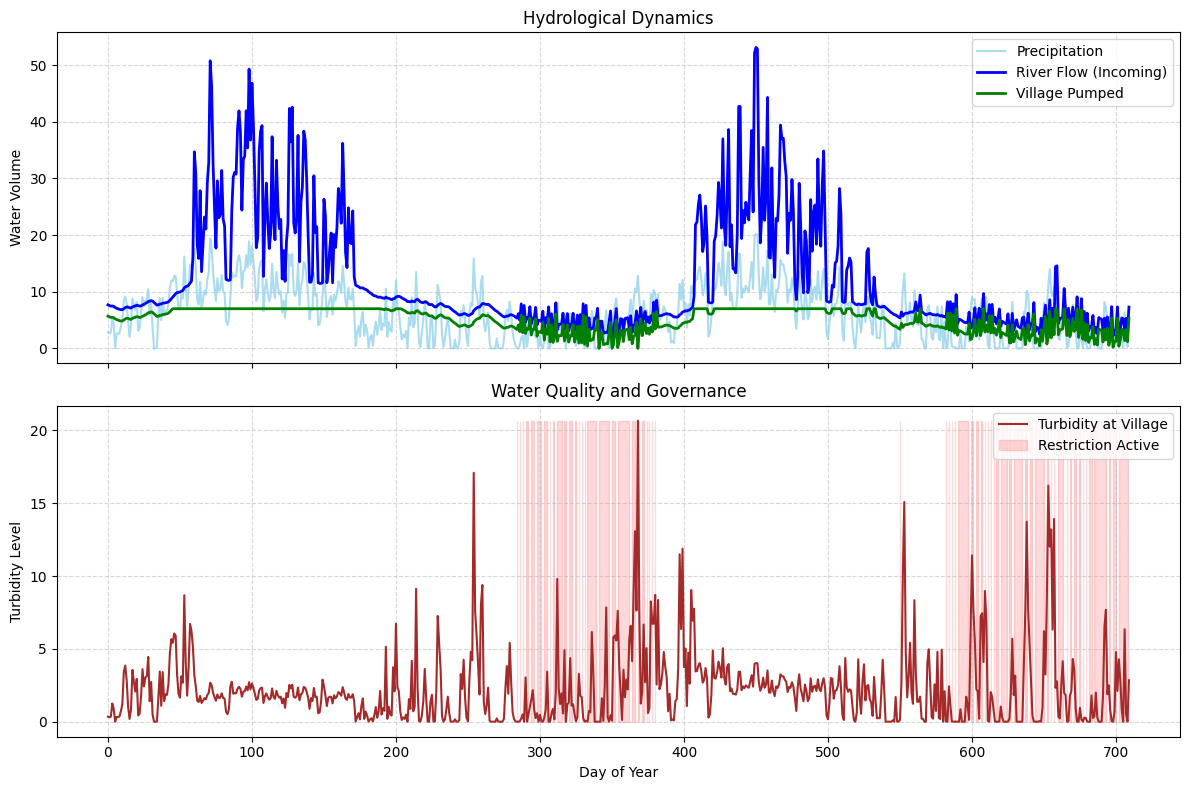


--- OPENMOLE OUTPUT DICTIONARY ---
system_stress_days: 164
eco_violations: 2
economic_treatment_cost: 3874.93
village_thirst_days: 450
yield_expander_top_pct: 93.66
yield_traditional_mid_pct: 78.03
yield_expander_bot_pct: 92.82


In [87]:
# =====================================================================
# OPENMOLE INTERFACE (Inputs & Simulation Wrapper)
# =====================================================================

# Defining parameters here for OpenMOLE
SCENARIO_INPUTS = {
    # Time & Environment
    "days_to_simulate": 710,
    "daily_evaporation": 1.0,
    
    # Climate Engine
    "humid_length": 180,
    "p_peak": 8.0,
    "p_base": 3.3,
    "rho": 0.6,
    "sigma": 3.0,
    
    # Parcel Physics
    "s_max": 400.0,
    "beta": 0.015,
    "k_erosion": 0.25,
    
    # Village Governance
    "village_demand": 7.0,
    "min_env_flow": 2.0,
    "humanitarian_threshold": 0.5,
    
    # Farmer Spatial Distribution
    "farmer_profiles": ["Expander", "Traditionalist", "Expander"]
}


def run_simulation(inputs, plot=False):
    """ Runs the ABM using the input dictionary and returns an output dictionary. """
    random.seed(42) 
    
    # 1. Initialize Objects using Inputs
    climate = ClimateEngine(
        humid_length=inputs["humid_length"], 
        p_peak=inputs["p_peak"], 
        p_base=inputs["p_base"],
        rho=inputs["rho"],
        sigma=inputs["sigma"]
    )
    
    parcels = [
        Parcel(0, inputs["s_max"], inputs["beta"], inputs["k_erosion"]), 
        Parcel(1, inputs["s_max"], inputs["beta"], inputs["k_erosion"]), 
        Parcel(2, inputs["s_max"], inputs["beta"], inputs["k_erosion"])
    ]
    
    farmers = [
        Farmer(0, inputs["farmer_profiles"][0], parcels[0]),       
        Farmer(1, inputs["farmer_profiles"][1], parcels[1]), 
        Farmer(2, inputs["farmer_profiles"][2], parcels[2])        
    ]
    
    mamoudzou = Village(
        demand=inputs["village_demand"], 
        min_env_flow=inputs["min_env_flow"], 
        humanitarian_threshold=inputs["humanitarian_threshold"]
    )

    # Tracker variables for optional plotting
    history = {"days": [], "rain": [], "river": [], "pumped": [], "turbidity": [], "restriction": []}
    
    # 2. Main Simulation Loop
    for day in range(inputs["days_to_simulate"]):
        precip = climate.step()
        restriction_today = mamoudzou.upstream_restriction_active
        
        current_q_in = 0.0
        current_sed_in = 0.0
        current_turbidity = 0.0
        
        for i in range(len(parcels)):
            p = parcels[i]
            f = farmers[i]
            
            w_avail = p.get_available_water(precip, current_q_in, inputs["daily_evaporation"])
            pump = f.make_daily_decision(restriction_today, w_avail)
            
            q_out, total_sed, t_out = p.step_hydrology(precip, current_q_in, current_sed_in, inputs["daily_evaporation"], pump)
            current_q_in = q_out
            current_sed_in = total_sed
            current_turbidity = t_out
            
        v_pumped, flow_to_ocean, treatment_cost = mamoudzou.process_daily_water(current_q_in, current_turbidity)
        
        if plot:
            history["days"].append(day)
            history["rain"].append(precip)
            history["river"].append(current_q_in)
            history["pumped"].append(v_pumped)
            history["turbidity"].append(current_turbidity)
            history["restriction"].append(1 if mamoudzou.upstream_restriction_active else 0)

    # 3. Calculate Final Output Metrics (The KPI Dictionary)
    
    # Yield = % of days the crop received its full water demand
    yield_f0 = round(((inputs["days_to_simulate"] - farmers[0].stress_days) / inputs["days_to_simulate"]) * 100, 2)
    yield_f1 = round(((inputs["days_to_simulate"] - farmers[1].stress_days) / inputs["days_to_simulate"]) * 100, 2)
    yield_f2 = round(((inputs["days_to_simulate"] - farmers[2].stress_days) / inputs["days_to_simulate"]) * 100, 2)

    outputs = {
    "system_stress_days": mamoudzou.upstream_restriction_days,         # Number of days water restrictions were declared (system stress)
    "eco_violations": mamoudzou.eco_violations,                        # Days flow at the outlet violated the minimum environmental flow
    "economic_treatment_cost": round(mamoudzou.total_treatment_cost, 2), # Downstream water treatment costs driven by upstream turbidity
    "village_thirst_days": mamoudzou.thirst_days,                      # Days the villagers could not pump their full water demand
    "yield_expander_top_pct": yield_f0,                                # Harvest yield (%) for the monoculture farmer at the top
    "yield_traditional_mid_pct": yield_f1,                             # Harvest yield (%) for the polyculture farmer in the middle
    "yield_expander_bot_pct": yield_f2                                 # Harvest yield (%) for the monoculture farmer at the bottom
}
    
    # 4. Optional Plotting (Disable this when running in OpenMOLE)
    if plot:
        fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(12, 8), sharex=True)
        ax1.plot(history["days"], history["rain"], label='Precipitation', color='skyblue', alpha=0.7)
        ax1.plot(history["days"], history["river"], label='River Flow (Incoming)', color='blue', linewidth=2)
        ax1.plot(history["days"], history["pumped"], label='Village Pumped', color='green', linewidth=2)
        ax1.set_ylabel('Water Volume')
        ax1.set_title('Hydrological Dynamics')
        ax1.legend(loc='upper right')
        ax1.grid(True, linestyle='--', alpha=0.5)

        ax2.plot(history["days"], history["turbidity"], label='Turbidity at Village', color='brown', linewidth=1.5)
        ax2.fill_between(history["days"], 0, max(history["turbidity"]), where=[r == 1 for r in history["restriction"]], color='red', alpha=0.15, label='Restriction Active')
        ax2.set_xlabel('Day of Year')
        ax2.set_ylabel('Turbidity Level')
        ax2.set_title('Water Quality and Governance')
        ax2.legend(loc='upper right')
        ax2.grid(True, linestyle='--', alpha=0.5)
        plt.tight_layout()
        plt.show()

    return outputs

# =====================================================================
# 3. EXECUTION
# =====================================================================

if __name__ == "__main__":
    # Run a single instance with plots for visual testing
    final_results = run_simulation(SCENARIO_INPUTS, plot=True)
    
    print("\n--- OPENMOLE OUTPUT DICTIONARY ---")
    for key, value in final_results.items():
        print(f"{key}: {value}")

Running OAT Sensitivity Analysis (averaging 10 stochastic runs per point)...


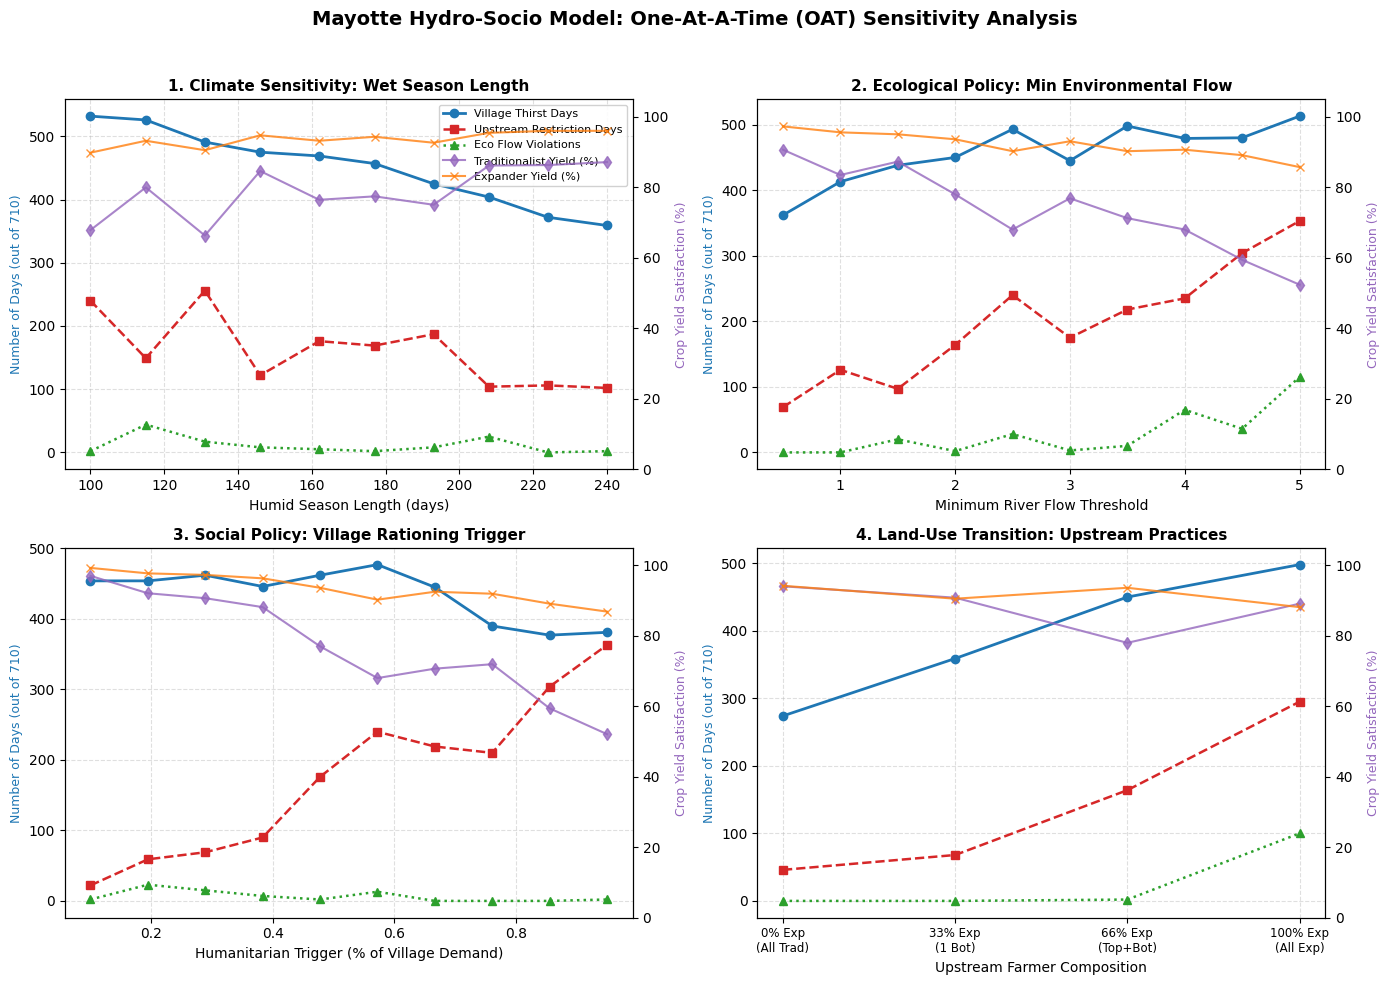

Generating 2D Climate vs. Governance Phase Diagram...


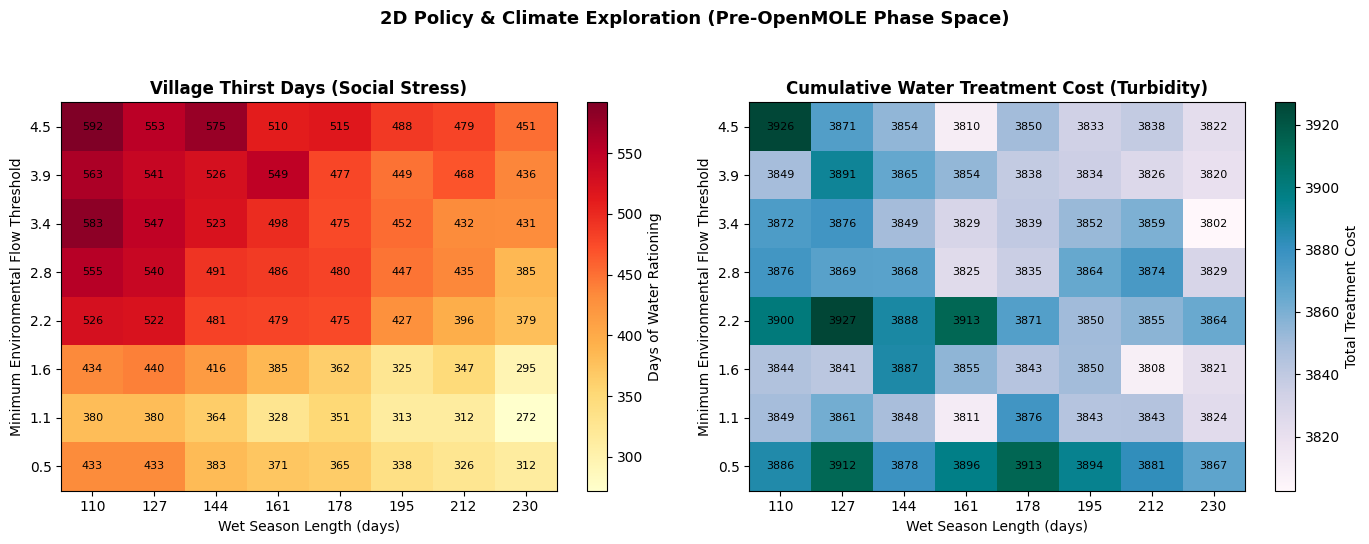

In [88]:
import copy
import numpy as np
import matplotlib.pyplot as plt

# =====================================================================
# 4. SENSITIVITY ANALYSIS & PHASE DIAGRAM VISUALIZATION
# =====================================================================

def run_monte_carlo_average(base_inputs, overrides, n_seeds=10):
    """
    Runs the simulation multiple times with different random weather seeds
    to isolate structural parameter sensitivity from stochastic AR1 noise.
    """
    agg_outputs = {}
    
    for seed in range(n_seeds):
        # Create a clean copy of inputs and apply parameter overrides
        sim_inputs = copy.deepcopy(base_inputs)
        sim_inputs.update(overrides)
        
        # Temporarily patch random.seed inside run_simulation by setting global seed
        # Note: For cleaner seeds, ensure run_simulation accepts an optional 'seed' arg,
        # or remove the hardcoded random.seed(42) inside run_simulation().
        random.seed(seed * 100 + 7)
        res = run_simulation(sim_inputs, plot=False)
        
        for k, v in res.items():
            agg_outputs[k] = agg_outputs.get(k, 0.0) + (v / n_seeds)
            
    return agg_outputs


def plot_sensitivity_analysis(base_inputs, n_seeds=10):
    """
    Generates a 4-panel One-At-A-Time (OAT) sensitivity analysis figure
    and a 2D Climate vs. Governance heatmap.
    """
    print(f"Running OAT Sensitivity Analysis (averaging {n_seeds} stochastic runs per point)...")

    # Define the 4 parameter sweeps to explore
    sweeps = [
        {
            "param": "humid_length",
            "title": "1. Climate Sensitivity: Wet Season Length",
            "xlabel": "Humid Season Length (days)",
            "values": np.linspace(100, 240, 10, dtype=int),
            "is_profile": False
        },
        {
            "param": "min_env_flow",
            "title": "2. Ecological Policy: Min Environmental Flow",
            "xlabel": "Minimum River Flow Threshold",
            "values": np.linspace(0.5, 5.0, 10),
            "is_profile": False
        },
        {
            "param": "humanitarian_threshold",
            "title": "3. Social Policy: Village Rationing Trigger",
            "xlabel": "Humanitarian Trigger (% of Village Demand)",
            "values": np.linspace(0.1, 0.95, 10),
            "is_profile": False
        },
        {
            "param": "farmer_profiles",
            "title": "4. Land-Use Transition: Upstream Practices",
            "xlabel": "Upstream Farmer Composition",
            "values": [
                ["Traditionalist", "Traditionalist", "Traditionalist"],
                ["Traditionalist", "Traditionalist", "Expander"],
                ["Expander", "Traditionalist", "Expander"],
                ["Expander", "Expander", "Expander"]
            ],
            "xlabels_custom": ["0% Exp\n(All Trad)", "33% Exp\n(1 Bot)", "66% Exp\n(Top+Bot)", "100% Exp\n(All Exp)"],
            "is_profile": True
        }
    ]

    # --- FIGURE 1: 4-Panel OAT Sensitivity Curves ---
    fig, axes = plt.subplots(2, 2, figsize=(14, 10))
    axes = axes.flatten()

    for idx, sweep in enumerate(sweeps):
        ax = axes[idx]
        ax_twin = ax.twinx()  # Secondary y-axis for Treatment Cost & Yields

        thirst_list, restrict_list, eco_list = [], [], []
        cost_list, yield_trad_list, yield_exp_list = [], [], []

        for val in sweep["values"]:
            override_val = val if sweep["is_profile"] else float(val)
            if sweep["param"] == "humid_length":
                override_val = int(val)
                
            res = run_monte_carlo_average(base_inputs, {sweep["param"]: override_val}, n_seeds=n_seeds)
            
            thirst_list.append(res["village_thirst_days"])
            restrict_list.append(res["system_stress_days"])
            eco_list.append(res["eco_violations"])
            cost_list.append(res["economic_treatment_cost"])
            yield_trad_list.append(res["yield_traditional_mid_pct"])
            yield_exp_list.append(res["yield_expander_top_pct"])

        x_axis = range(len(sweep["values"])) if sweep["is_profile"] else sweep["values"]

        # Left Axis: Days (Thirst, Restrictions, Eco Violations)
        l1 = ax.plot(x_axis, thirst_list, 'o-', color='#1f77b4', linewidth=2, label='Village Thirst Days')
        l2 = ax.plot(x_axis, restrict_list, 's--', color='#d62728', linewidth=1.8, label='Upstream Restriction Days')
        l3 = ax.plot(x_axis, eco_list, '^:', color='#2ca02c', linewidth=1.8, label='Eco Flow Violations')

        # Right Axis: Treatment Cost (scaled /10 for visual alignment) & Yields
        l4 = ax_twin.plot(x_axis, yield_trad_list, 'd-', color='#9467bd', alpha=0.8, label='Traditionalist Yield (%)')
        l5 = ax_twin.plot(x_axis, yield_exp_list, 'x-', color='#ff7f0e', alpha=0.8, label='Expander Yield (%)')

        ax.set_title(sweep["title"], fontsize=11, fontweight='bold')
        ax.set_xlabel(sweep["xlabel"], fontsize=10)
        ax.set_ylabel("Number of Days (out of 710)", fontsize=9, color='#1f77b4')
        ax_twin.set_ylabel("Crop Yield Satisfaction (%)", fontsize=9, color='#9467bd')
        ax_twin.set_ylim(0, 105)
        ax.grid(True, linestyle='--', alpha=0.4)

        if sweep["is_profile"]:
            ax.set_xticks(x_axis)
            ax.set_xticklabels(sweep["xlabels_custom"], fontsize=8.5)

        # Combine legends on the first subplot only to keep it clean
        if idx == 0:
            lines = l1 + l2 + l3 + l4 + l5
            labels = [l.get_label() for l in lines]
            ax.legend(lines, labels, loc='upper right', fontsize=8, framealpha=0.9)

    plt.suptitle("Mayotte Hydro-Socio Model: One-At-A-Time (OAT) Sensitivity Analysis", fontsize=14, fontweight='bold')
    plt.tight_layout(rect=[0, 0, 1, 0.96])
    plt.show()

    # --- FIGURE 2: 2D Non-Linear Phase Diagram (Climate vs. Governance) ---
    print("Generating 2D Climate vs. Governance Phase Diagram...")
    humid_grid = np.linspace(110, 230, 8, dtype=int)
    env_flow_grid = np.linspace(0.5, 4.5, 8)
    
    thirst_matrix = np.zeros((len(env_flow_grid), len(humid_grid)))
    cost_matrix = np.zeros((len(env_flow_grid), len(humid_grid)))

    for i, min_q in enumerate(env_flow_grid):
        for j, h_len in enumerate(humid_grid):
            res = run_monte_carlo_average(
                base_inputs, 
                {"humid_length": int(h_len), "min_env_flow": float(min_q)}, 
                n_seeds=max(5, n_seeds // 2)
            )
            thirst_matrix[i, j] = res["village_thirst_days"]
            cost_matrix[i, j] = res["economic_treatment_cost"]

    fig2, (ax_h1, ax_h2) = plt.subplots(1, 2, figsize=(14, 5.5))

    # Heatmap 1: Village Thirst Days
    im1 = ax_h1.imshow(thirst_matrix, origin='lower', aspect='auto', cmap='YlOrRd')
    ax_h1.set_xticks(range(len(humid_grid)))
    ax_h1.set_xticklabels(humid_grid)
    ax_h1.set_yticks(range(len(env_flow_grid)))
    ax_h1.set_yticklabels([f"{q:.1f}" for q in env_flow_grid])
    ax_h1.set_xlabel("Wet Season Length (days)")
    ax_h1.set_ylabel("Minimum Environmental Flow Threshold")
    ax_h1.set_title("Village Thirst Days (Social Stress)", fontweight='bold')
    fig2.colorbar(im1, ax=ax_h1, label="Days of Water Rationing")

    # Annotate cells with exact numbers
    for i in range(len(env_flow_grid)):
        for j in range(len(humid_grid)):
            ax_h1.text(j, i, f"{int(thirst_matrix[i, j])}", ha="center", va="center", color="black", fontsize=8)

    # Heatmap 2: Economic Water Treatment Cost
    im2 = ax_h2.imshow(cost_matrix, origin='lower', aspect='auto', cmap='PuBuGn')
    ax_h2.set_xticks(range(len(humid_grid)))
    ax_h2.set_xticklabels(humid_grid)
    ax_h2.set_yticks(range(len(env_flow_grid)))
    ax_h2.set_yticklabels([f"{q:.1f}" for q in env_flow_grid])
    ax_h2.set_xlabel("Wet Season Length (days)")
    ax_h2.set_ylabel("Minimum Environmental Flow Threshold")
    ax_h2.set_title("Cumulative Water Treatment Cost (Turbidity)", fontweight='bold')
    fig2.colorbar(im2, ax=ax_h2, label="Total Treatment Cost")

    for i in range(len(env_flow_grid)):
        for j in range(len(humid_grid)):
            ax_h2.text(j, i, f"{int(cost_matrix[i, j])}", ha="center", va="center", color="black", fontsize=8)

    plt.suptitle("2D Policy & Climate Exploration (Pre-OpenMOLE Phase Space)", fontsize=13, fontweight='bold')
    plt.tight_layout(rect=[0, 0, 1, 0.94])
    plt.show()


# =====================================================================
# 5. EXECUTION
# =====================================================================
if __name__ == "__main__":
    # IMPORTANT: Remove or comment out `random.seed(42)` inside `run_simulation()`
    # so `run_monte_carlo_average()` can test multiple stochastic weather realizations!
    plot_sensitivity_analysis(SCENARIO_INPUTS, n_seeds=10)